<h1 style="color:red" align = center>INTRODUCTION TO MACHINE LEARNING</h1>
<h1 style="color:red" align = center> ChurnGuard GROUP PROJECT </h1>
<h2 style="color:red"align = center>Instructor: Dr. Khaled Mohamad</h2>

### TEAM ROLES:

<table style="text-align:left">
<tr>
    <th>Member</th>
    <th>Student ID</th>
    <th>Role</th>
</tr>
<tr>
    <td>Tairuly Nursat</td>
    <td>24B031110</td>
    <td>EDA Lead</td>
</tr>
<tr>
    <td>Gaukarbek Akmaral</td>
    <td>24B031725</td>
    <td>Modelling Lead</td>
</tr>
<tr>
    <td>Bayandiev Alibek</td>
    <td>24B031696</td>
    <td>Report & Presentation Lead</td>
</tr>
</table>

In [1]:
# Imports of dataset and needed libraries. 
import pandas as pd
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
import numpy as np
from scipy.stats import chi2_contingency

import warnings 
warnings.filterwarnings("ignore")

df = pd.read_csv("Customer_Churn.csv") 

#  ОТСЮДА НАЧИНАЯ Я ВООБЩЕ ПЕРЕСТАНУ ОБРАЩАТЬ ВНИМАНИЕ НА ОФОРМЛЕНИЕ ОБЩИЕ ЗАМЕТКИ БУДУ ТОЛЬКО ОСТАВЛЯТЬ И У МЕНЯ МОГУТ БЫТЬ ОШИБКИ В ГРАММАТИКЕ ЕСЛИ ИХ ЗАМЕТИШЬ ИСПРАВЬ ИХ ТОЖЕ ПЖ А ОФОРМЛЕНИЕ ПРИМЕРНО ТО ЖЕ САМОЕ СДЕЛАЙ КАК ВО ВСЕМ ФАЙЛЕ
---
# ЦВЕТА < h4 style="color:brown" >
## СИНИЙ - ЗАГАЛОВОК
## ОРАНЖЕВЫЙ - ЧТО ТО ВАЖНОЕ
## КОРИЧНЕВЫЙ - ЧТО ТО ТОЖЕ ВАЖНОЕ НО НЕ ТАКОЕ ВАЖНОЕ КАК ОРАНЖЕВЫЙ
---
# ОБОЗНАЧЕНИЯ
## ``(< code >< /code >) ДЛЯ ЗНАЧЕНИЯ ТАБЛИЦ
## ** ** ДЛЯ ЧЕГО ТО ВАЖНОГО ИЛИ ЦИФР
## * * ДЛЯ МЕНЕЕ ВАЖНОГО
---
# //////// для чего то нового что я в текст добавил 
# Я НЕ БУДУ ДАВАТЬ НАЗВАНИЯ ЗАГАЛОВКАМ ПРОСТО ??? КРОМЕ КОНКЛЮШН 
Если кажется что расположение текста не очень можешь переставлять.
P/S И спс что поможешь :)

<h2 style="color:blue">1. Dataset Overview.</h2>

We used the **Iranian Churn** dataset from the UCI Machine Learning Repository:
`https://archive.ics.uci.edu/dataset/563/iranian+churn+dat`.
<br>The dataset contains customer information from an Iranian telecommunications company. It has **3150 rows** and **14 columns**: 13 features and one target column(`Churn`).

**Problem type:** classification.

**Target variable:** `Churn` - whether a customer leaves the company (`Churn = 1`) or stays (`Churn = 0`).



In [2]:
display(df.shape)
display(df.head())

(3150, 14)

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


<h3 style="color:blue">1.1 Data Types Overview</h2>

<h4 style="color:orange">Our data consists of numerical dtypes.</h4>

We can divide our dataset column dtypes into 3 types:
- **Binary**(True/False, but using Integers)**:**
  - *1/0:*
    - `Complains`(had/ didn't have)
    - `Churn`(left/ stayed)
  - *2/1:*
    - `Tariff Plan`(contractual/ pay as you go)
    - `Status`(active/ non-active)
- **Common Integer:**
  - *With Limits:*
      - `Charge  Amount`(min - 0, max - 10)
      - `Age Group`(min - 1, max - 5)
  - *Without Limits:*
      - `Age`
      - `Call  Failures`
      - `Subscription Length`(months)
      - `Seconds of Use`
      - `Frequency of use`(total number of calls)
      - `Frequency of SMS`
      - `Distinct Called Numbers`
- **Flaot:**
  - `Customer Value`(The calculated value of customer)

//////////////////////////
In summary, we can divide our dataframe columns into 3 types such as: Binary, Integers, Float. Also, as you can see above this summary is more detailed explanation of not understandable columns or columns with limitations. First problem with dataframe is that, we didn't liked it's unification problem. For example, if I call Call  Failure it can give error because in unmodified data it has 2 spaces, but when I call Tariff Plan it has only 1 space. Same problem for Binary we 1/0 notation + 2/1 notation, but here is some sort of logic(1/0 only T/F, while 2/1), but overall it's confusing. This problems are inconsistent and cause our group to waste our time or program logic completely wrong.
/////////////////////
We should try to standartize everything, so we will fix this problems by modifying our data, when we will clean data.
//////////////////////////

We can observe that `df.info()` and `df.describe()`confirm that our words about division of numerical dtypes are **True**./////////<=(1 tekst)  We can clearly see that min and max values for Common Integers with limits are exact as in above statements. Also you can observe by min and max values that we really have Binary type columns. Moreover, we can see the trend, mean(avg) is more than median(50%) for Charge  Amount, Seconds of Use, and etc.(except Subscription  Length and Age Group), which means most of our columns are likely positively skewed.  	 /////////////
Also we can see that there is **no missing values**.


*Our main prediction is that customers who **have filed complaints** and **experienced more call failures** are **more likely to churn** than customers who have not complained and experienced fewer call failures.*
<h4 style="color:brown">Detailed anaylysis of Target variable(<code>Churn</code>) is provided in section 3.</h4>

In [17]:
display(df.info())
display(df.describe()) 
display(df.dtypes)
display(df.isnull().sum())

print("Complains unique values:", df["Complains"].unique())
print("Churn unique values:", df["Churn"].unique())
print("Tariff Plan unique values:", df["Tariff Plan"].unique())
print("Status unique values:", df["Status"].unique())
print("Charge  Amount unique values:", np.sort(df["Charge  Amount"].unique()))
print("Age Group unique values:", np.sort(df["Age Group"].unique()))



<class 'pandas.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Call  Failure            3150 non-null   int64  
 1   Complains                3150 non-null   int64  
 2   Subscription  Length     3150 non-null   int64  
 3   Charge  Amount           3150 non-null   int64  
 4   Seconds of Use           3150 non-null   int64  
 5   Frequency of use         3150 non-null   int64  
 6   Frequency of SMS         3150 non-null   int64  
 7   Distinct Called Numbers  3150 non-null   int64  
 8   Age Group                3150 non-null   int64  
 9   Tariff Plan              3150 non-null   int64  
 10  Status                   3150 non-null   int64  
 11  Age                      3150 non-null   int64  
 12  Customer Value           3150 non-null   float64
 13  Churn                    3150 non-null   int64  
dtypes: float64(1), int64(13)
memory usa

None

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
count,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000
mean,7.627937,0.076508,32.541905,0.942857,4472.459683,69.460635,73.174921,23.509841,2.826032,1.077778,1.248254,30.998413,470.972916,0.157143
std,7.263886,0.265851,8.573482,1.521072,4197.908687,57.413308,112.237560,17.217337,0.892555,0.267864,0.432069,8.831095,517.015433,0.363993
min,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,15.000000,0.000000,0.000000
25%,1.000000,0.000000,30.000000,0.000000,1391.250000,27.000000,6.000000,10.000000,2.000000,1.000000,1.000000,25.000000,113.801250,0.000000
50%,6.000000,0.000000,35.000000,0.000000,2990.000000,54.000000,21.000000,21.000000,3.000000,1.000000,1.000000,30.000000,228.480000,0.000000
75%,12.000000,0.000000,38.000000,1.000000,6478.250000,95.000000,87.000000,34.000000,3.000000,1.000000,1.000000,30.000000,788.388750,0.000000
max,36.000000,1.000000,47.000000,10.000000,17090.000000,255.000000,522.000000,97.000000,5.000000,2.000000,2.000000,55.000000,2165.280000,1.000000


Call  Failure                int64
Complains                    int64
Subscription  Length         int64
Charge  Amount               int64
Seconds of Use               int64
Frequency of use             int64
Frequency of SMS             int64
Distinct Called Numbers      int64
Age Group                    int64
Tariff Plan                  int64
Status                       int64
Age                          int64
Customer Value             float64
Churn                        int64
dtype: object

Call  Failure              0
Complains                  0
Subscription  Length       0
Charge  Amount             0
Seconds of Use             0
Frequency of use           0
Frequency of SMS           0
Distinct Called Numbers    0
Age Group                  0
Tariff Plan                0
Status                     0
Age                        0
Customer Value             0
Churn                      0
dtype: int64

Complains unique values: [0 1]
Churn unique values: [0 1]
Tariff Plan unique values: [1 2]
Status unique values: [1 2]
Charge  Amount unique values: [ 0  1  2  3  4  5  6  7  8  9 10]
Age Group unique values: [1 2 3 4 5]


<h2 style="color:blue">2. Data cleaning</h3>

<h3 style="color:blue">2.1 Missing-values and Duplicates check</h3>

In [4]:
display(df.isnull().sum())
display(df.duplicated().sum())
df[df.duplicated()]

Call  Failure              0
Complains                  0
Subscription  Length       0
Charge  Amount             0
Seconds of Use             0
Frequency of use           0
Frequency of SMS           0
Distinct Called Numbers    0
Age Group                  0
Tariff Plan                0
Status                     0
Age                        0
Customer Value             0
Churn                      0
dtype: int64

np.int64(300)

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
518,0,0,37,0,0,0,0,0,2,1,2,25,0.00,1
628,0,0,35,0,0,0,0,0,2,1,2,25,0.00,1
718,0,0,37,0,0,0,0,0,2,1,2,25,0.00,1
728,0,0,36,0,0,0,0,0,3,1,2,30,0.00,1
901,0,0,38,0,0,0,0,0,2,1,2,25,0.00,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3145,21,0,19,2,6697,147,92,44,2,2,1,25,721.98,0
3146,17,0,17,1,9237,177,80,42,5,1,1,55,261.21,0
3147,13,0,18,4,3157,51,38,21,3,1,1,30,280.32,0
3148,7,0,11,2,4695,46,222,12,3,1,1,30,1077.64,0


<h3 style="color:blue">2.2 Actual Data cleaning.</h3>

In [5]:
df_clean = df.copy()


df_clean.drop_duplicates(inplace=True)
df_clean.rename(columns={'Call  Failure': 'Call Failure', 'Subscription  Length': 'Subscription Length', 'Charge  Amount': 'Charge Amount'}, inplace=True)
df_clean["Tariff Plan"] = df_clean["Tariff Plan"] - 1
df_clean["Status"] = df_clean["Status"] - 1


display(df_clean.shape)
display(df["Churn"].value_counts())
display(df_clean["Churn"].value_counts())
df_clean.head()

(2850, 14)

Churn
0    2655
1     495
Name: count, dtype: int64

Churn
0    2404
1     446
Name: count, dtype: int64

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,0,0,30,197.640,0
1,0,0,39,0,318,5,7,4,2,0,1,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,0,0,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,0,0,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,0,0,15,145.805,0


<h3 style="color:blue">2.3 Ghost Customers Problem</h3>

In [6]:
df_ghost = df_clean[df_clean["Customer Value"] == 0]
display(df_ghost["Churn"].value_counts())

Churn
1    44
0    41
Name: count, dtype: int64

////////While we investigated values inside dataframe, we found a problem that there is customers who have 0 Frequency of use, Frequency of SMS, Customer Value. Now, we checked our dataframe for Churn to confirm that this rows aren't really necessary to drop. So we won't touch them.

<h3 style="color:blue">2.4 Overall Conclusion</h3>

We checked the dataframe for:
- *Missing-values*: **0 missing-values**
<br>There is no missing-values, so there is no reason to delete any row here.
<h4 style="color:orange">No imputation strategy is required, there is no missing-values, so there is no rows to edit here.(Не доразвитая идея)</h4>

- *Duplicates*: **300 duplicates**
<br>We need to prevent **data leakage**, because of duplicates. We will solve this problem by deleting duplicates.
<br>After we cleaned our data, the data now has **2850 rows** instead of **3150**.
<table style="text-align:left">
<tr>
    <th>Before</th>
    <th>After</th>
</tr>
<tr>
    <td>3150 rows</td>
    <td>2850 rows</td>
</tr>
<tr>
    <td>100% of data</td>
    <td>90.5% of data</td>
</tr>
<tr>
    <td>495 stayed</td>
    <td>446 stayed</td>
</tr>
<tr>
    <td>Rate of Churn is 15.7%</td>
    <td>Rate of Churn is 15.6%</td>
</tr>
</table>



Also, we thought there can be **hidden problem** with **Ghost Customers**(Customers, who have 0 in `Frequency of use`	`Frequency of SMS`, `Customer Value`), because they can lead to **data leakage**, so  

<h2 style="color:blue">3. Hypotesis test and Churn analysis</h2>

*We hypothesize that customers who **have filed complaints** and **experienced more call failures** are **more likely to churn** than customers who have not complained and experienced fewer call failures.*

It is hard to **visualize** `Call Failure`, so created a new column `High  Failure`, which means the dataset now has **15 columns** instead of **14**.

In [7]:
df_clean["Churn"].value_counts()

Churn
0    2404
1     446
Name: count, dtype: int64

<h3 style="color:blue">3.1 Churn X Complains connection</h3>

<Axes: xlabel='Complains', ylabel='Churn'>

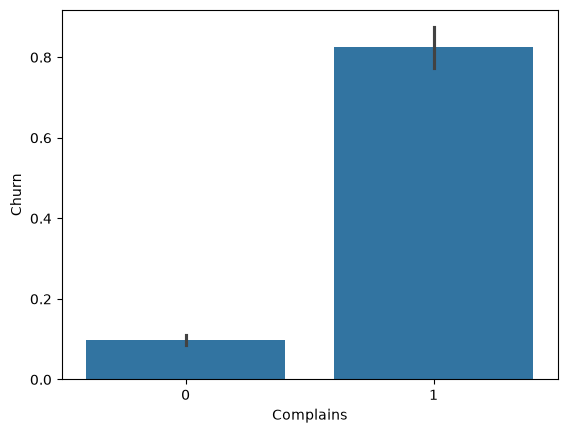

In [8]:
sns.barplot(data=df_clean, x='Complains', y='Churn')

////////////////////Our Barplots visualizations of Complains with Churn say that Complains has a huge influence on Churn. The difference between Complains and no Complains is huge ~0.7 and it all happens in binary column as Churn.

<h3 style="color:blue">3.2 Churn X High Failure connection</h3>

<Axes: xlabel='High Failure', ylabel='Churn'>

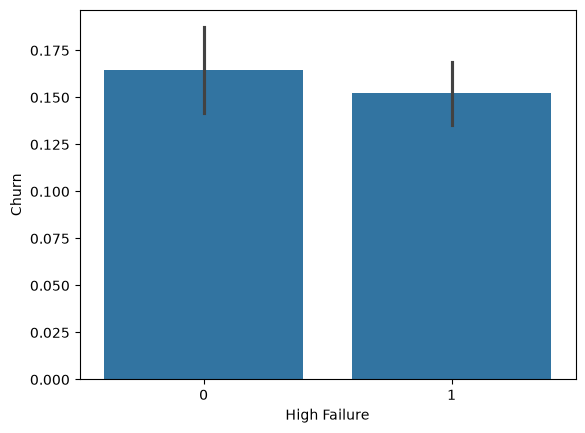

In [9]:
df_clean["High Failure"] = (df_clean["Call Failure"] > (df_clean["Call Failure"].median()/2)).astype("int")
sns.barplot(data=df_clean, x='High Failure', y='Churn')

///////////////////Our Barplots visualizations of High  Failure with Churn say that High  Failure doesn't affect Churn too much. Low  Failure and High Failure difference is ~0.13. It's morelikely there will be problem with our Hypothesis.

<h3 style="color:blue">3.3 Crosstable with both Complains and High Failure and its Analysis</h3>

We created a crosstab with both `Complains` and `High Failure`, and we can clearly see that:
- Customers who *didn't experience many failures* and *didn't have any complaints* have only **12% of Churn**.
- Customers who *didn't experience many failures* but *had complaints* have **98% of Churn**.
- Customers who *experienced many failures* but *didn't have any complaints* have **9% of Churn**.
- Customers who *experienced many failures* and *had complaints* have **78% of Churn**.

In [10]:
crossCompAFail = pd.crosstab(df_clean["Churn"], [df_clean["High Failure"],df_clean["Complains"]] , margins = True)
crossCompAFail

High Failure    0         1        All
Complains       0   1     0    1      
Churn                                 
0             807   1  1557   39  2404
1             110  49   146  141   446
All           917  50  1703  180  2850

<h3 style="color:blue">3.4 Conclusion for 1st Part</h3>

Our hypothesis is only partly true:
- **True:** We can observe that customers who *had any complaints* have a **higher percentage of Churn**.
- **False:** We can observe that even if customers *experienced many failures*, they still have a **lower percentage of Churn**.

<h3 style="color:blue">3.5 Why our Hypothesis doesn't work properly</h3>

<h3 style="color:orange">There is a lot of possibilities, here they are:</h3>

- <h4 style="color:brown">There is a possibility that this is because we concentrated only on the number of <code>Call  Failure</code>, not on the percentage of <code>Call  Failure</code> among <code>Frequency of use</code>.</h4>

In [11]:
df_High_Failure = df_clean[(df_clean["High Failure"] == 1)]
df_Low_Failure = df_clean[(df_clean["High Failure"] == 0)]

df_High_Failure_no0Calls = df_High_Failure[df_High_Failure["Frequency of use"] != 0]
df_Low_Failure_no0Calls = df_Low_Failure[df_Low_Failure["Frequency of use"] != 0]
df_no0Calls = df_clean[df_clean["Frequency of use"] != 0]
avg_FailsperCalls_HighF = (df_High_Failure_no0Calls["Call Failure"]/df_High_Failure_no0Calls["Frequency of use"]).mean()
avg_FailsperCalls_LowF = (df_Low_Failure_no0Calls["Call Failure"]/df_Low_Failure_no0Calls["Frequency of use"]).mean()
avg_FailsperCalls_AllDf =(df_no0Calls["Call Failure"]/(df_no0Calls["Frequency of use"])).mean()
print("The percetage for High Failure:", (avg_FailsperCalls_HighF*100).round(1),"%")
print("The percetage for Low Failure: ", (avg_FailsperCalls_LowF*100).round(2),"%")
print("The percetage for Df_clean:     ", (avg_FailsperCalls_AllDf*100).round(1),"%")

The percetage for High Failure: 19.6 %
The percetage for Low Failure:  3.65 %
The percetage for Df_clean:      14.6 %


#### Conclusion: 
Not a reason. Customers with `High  Failure` also have a high percentage of failures(**19.6%**), while customers with `Low  Failure`(`High  Failure` == 0) have a low percentage failures(**3.65%**).

- <h4 style="color:brown">There is a possibility that this is because customers are more loyal (<code>Subscription  Length</code> is high), so  it's hard for them to change their provider.</h4>

In [12]:
print("Avg Subscription Length for High  Failure:", (df_High_Failure["Subscription Length"]).mean().round(1),"months")
print("Avg Subscription Length for Low  Failure: ", (df_Low_Failure["Subscription Length"]).mean().round(1),"months")
print("Avg Subscription Length for Df_clean:     ", (df_clean["Subscription Length"]).mean().round(1),"months")

Avg Subscription Length for High  Failure: 33.6 months
Avg Subscription Length for Low  Failure:  30.3 months
Avg Subscription Length for Df_clean:      32.5 months


#### Conclusion: 
Not a reason. Customers have very similar `Subscription  Length` with only **3.3** months difference.

- <h4 style="color:brown">There is a possibility that this is because customers are older (<code>Age Group(min = 1(young), max = 5(old))</code> is high) and don't know how to change provider, so they don't leave.</h4>

In [13]:
print("Avg Age Group for High Failure:", (df_High_Failure["Age Group"]).mean().round(1))
print("Avg Age Group for Low Failure:", (df_Low_Failure["Age Group"]).mean().round(1))
print("Avg Age Group for whole Df_clean:", (df_clean["Age Group"]).mean().round(1))

Avg Age Group for High Failure: 2.9
Avg Age Group for Low Failure: 2.8
Avg Age Group for whole Df_clean: 2.8


#### Conclusion: 
Not a reason. Customers a have very similar `Age Group` with only **0.1** difference.

<h..>Let's visualize all left possibilities with heatmap.</>

<Axes: >

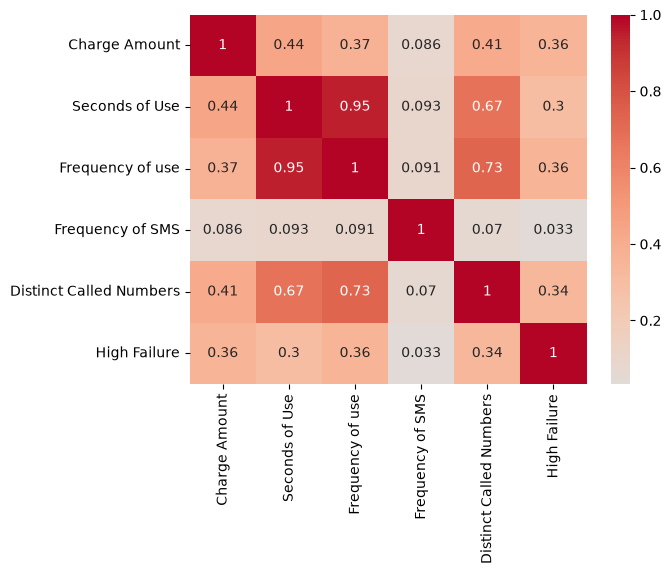

In [14]:
df_heat = df_clean.copy()
df_heat.drop(columns=["Call Failure", "Complains", "Subscription Length", "Age Group", "Tariff Plan", "Status", "Age", "Customer Value", "Churn" ], inplace=True,             errors = "ignore")
numeric_cols = df_heat.columns
sns.heatmap(df_heat[numeric_cols].corr(), annot=True, cmap = 'coolwarm', center = 0)

#### Conclusion: 
////////////////////////This is a reason. We can observe that practically all left columns(	Charge  Amount, Seconds of Use, Frequency of use, Distinct Called Numbers), except Frequency of SMS, have pretty deep relationship(~0.34) with High  Failure. So we can say that all left columns are connected with calls and this parameters caused our customers stay even if they have High  Failure. We could use heatmap at start, but if we did so, our heatmap would have too many parameters and so not readable.

In [15]:
df_heat.head()

,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,High Failure
0,0,4370,71,5,17,1
1,0,318,5,7,4,0
2,0,2453,60,359,24,1
3,0,4198,66,1,35,1
4,0,2393,58,2,33,0
